In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from numpy.linalg import eig

In [24]:
def hamiltonian(Omega, Delta, phi, V):

    H = np.array([[2*Delta, Omega*np.exp(-1j*phi),Omega*np.exp(-1j*phi), 0],
                  [Omega*np.exp(1j*phi), 0, 0, Omega*np.exp(-1j*phi)], 
                  [Omega*np.exp(1j*phi), 0, 0, Omega*np.exp(-1j*phi)], 
                  [0, Omega*np.exp(1j*phi), Omega*np.exp(1j*phi), -2*Delta + 2*V]])
    return H

In [42]:

V = 0
phi = 0
Delta = 0

In [43]:
H = hamiltonian(Omega, Delta, phi, V)

In [44]:
psi0 = np.array([1, 0, 0, 0])  # Initial

In [55]:
#Find eiegenvalues and eigenvectors of the Hamiltonian
def solve_static(H, psi0, times):
    eiegenvalues, eigenvectors = eig(H)
    coeffs = eigenvectors.conj().T @ psi0
    states = []
    for t in times:
        phase = np.exp(-1j * eiegenvalues * t)
        psi_t = eigenvectors @ (coeffs * phase)
        states.append(psi_t)
    return np.array(states)

In [56]:
#generate a time array
t_max = 5
times = np.linspace(0, t_max, 1000)

In [57]:
Omega = 2*np.pi
Delta = 0
phi = 0
V = 0

H = hamiltonian(Omega, Delta, phi, V)

states = solve_static(H, psi0, times)

In [58]:
P00 = np.abs(states[:,0])**2
P0r = np.abs(states[:,1])**2
Pr0 = np.abs(states[:,2])**2
Prr = np.abs(states[:,3])**2

In [59]:
total = P00 + P0r + Pr0 + Prr

print(np.max(np.abs(total-1)))

0.5


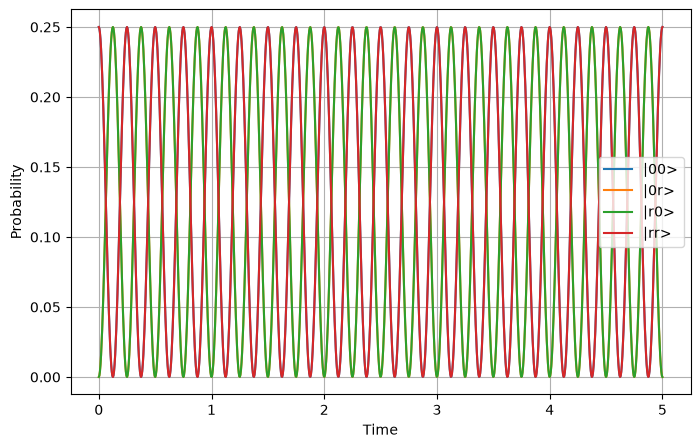

In [60]:
plt.figure(figsize=(8,5))

plt.plot(times, P00, label="|00>")
plt.plot(times, P0r, label="|0r>")
plt.plot(times, Pr0, label="|r0>")
plt.plot(times, Prr, label="|rr>")

plt.xlabel("Time")
plt.ylabel("Probability")
plt.legend()
plt.grid()

plt.show()

In [61]:
bell = np.array([
    0,
    1/np.sqrt(2),
    1/np.sqrt(2),
    0
], dtype=complex)

In [62]:
Pbell = []

for psi in states:

    overlap = np.vdot(
        bell,
        psi
    )

    Pbell.append(
        np.abs(overlap)**2
    )

Pbell = np.array(Pbell)

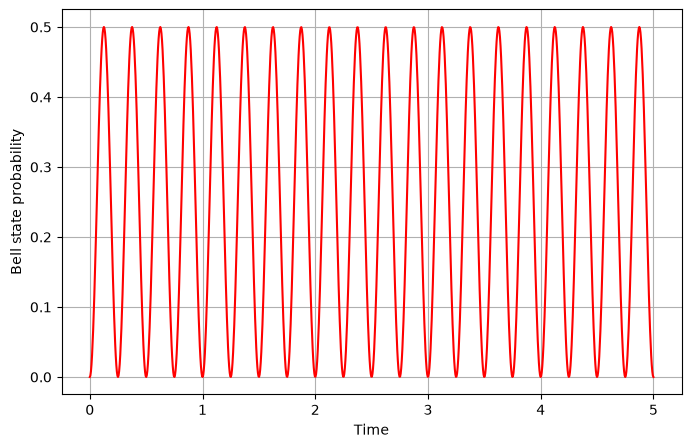

In [63]:
plt.figure(figsize=(8,5))

plt.plot(
    times,
    Pbell,
    color="red"
)

plt.xlabel("Time")
plt.ylabel("Bell state probability")
plt.grid()

plt.show()